# Text clustering on the IMDB dataset

In [74]:
# Importing necessary packages
import pandas as pd
import re
from tqdm import tqdm
import pickle
import matplotlib.pyplot as plt

import nltk
from nltk import pos_tag
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
nltk.download('wordnet')
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger') 

from sentence_transformers import SentenceTransformer

import gensim
from wordcloud import WordCloud

from sklearn.decomposition import PCA
from sklearn.manifold import LocallyLinearEmbedding

import pyLDAvis.gensim
import pyLDAvis

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\danie\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\danie\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\danie\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


In [31]:
df = pd.read_csv("movie_review.csv")[["id", "sentiment", "review"]]
df

,id,sentiment,review
0,5814_8,1,With all this stuff going down at the moment w...
1,2381_9,1,"\""The Classic War of the Worlds\"" by Timothy H..."
2,7759_3,0,The film starts with a manager (Nicholas Bell)...
3,3630_4,0,It must be assumed that those who praised this...
4,9495_8,1,Superbly trashy and wondrously unpretentious 8...
...,...,...,...
4995,3720_2,0,Is this film a joke? Is it a comedy? Surely it...
4996,4229_10,1,Don't waste time reading my review. Go out and...
4997,8042_3,0,"The secret is...this movie blows. Sorry, but i..."
4998,9669_9,1,After reading the original play I thought it w...


In [26]:
df.head()

,id,sentiment,review
0,5814_8,1,With all this stuff going down at the moment w...
1,2381_9,1,"\""The Classic War of the Worlds\"" by Timothy H..."
2,7759_3,0,The film starts with a manager (Nicholas Bell)...
3,3630_4,0,It must be assumed that those who praised this...
4,9495_8,1,Superbly trashy and wondrously unpretentious 8...


In [66]:
df["sentiment"].value_counts()

sentiment
1    2517
0    2483
Name: count, dtype: int64

# Preprocessing
Preprocessing is performed on each review. The following steps are taken:
- Lowercasing
- HTML tags are removed
- Punctuation is removed (without single quotes, as some stopwords contain single quotes, such as "you'll")
- Stopwords are removed
- Single quotes are removed
- Lemmatization using POS tagging (bringing words back to their root)

In [27]:
# Defining utilities that do not have to be defined all the time
le = WordNetLemmatizer()

# Define a function to get correct position input for the Lemmatizer.
def get_pos_code(x):
    if x.startswith('J'):
        return 'a'
    elif x.startswith('V'):
        return 'v'
    elif x.startswith('N'):
        return 'n'
    elif x.startswith('R'):
        return 'r'
    else:
        return 'n'

def preprocess_document(doc: str):
    """
    This function preprocesses a textual document into a bag of words.
    Applied steps:
    - Lowercasing
    - Removing HTML tags
    - Removing stopwords
    - Removing punctuation
    - Lemmatization

    """
    # Converting to lowercase
    doc = doc.lower()

    # Removing HTML tags
    doc = re.sub("</?[^>]+>", "", doc)

    # Removing punctuation, but ' (single quotes) are not removed (as stopwords may contain them.)
    punct = str.maketrans("", "", '!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~')
    doc = doc.translate(punct)

    # Removing stopwords
    doc = doc.split(" ")
    
    doc = [word for word in doc if word not in stopwords.words("English")]

    # Removing the single quote
    doc = " ".join(doc)
    punct = str.maketrans("", "", "'")
    doc = doc.translate(punct)
    doc = word_tokenize(doc)

    # Lemmatization
    doc = pos_tag(doc) # Pos tagging to improve lemmatization process.
    doc = [le.lemmatize(word, get_pos_code(tag)) for word, tag in doc]

    # Joining again into single string for final output
    doc = " ".join(doc)

    return doc
    
    


In [28]:
df["review_preprocessed"] = tqdm(df["review"].apply(preprocess_document))
# This takes a long time. 

KeyboardInterrupt: 

Now the dataset is preprocessed and (almost) completely clean. The result is: each document is converted to a bag of words containing only meaningful words.

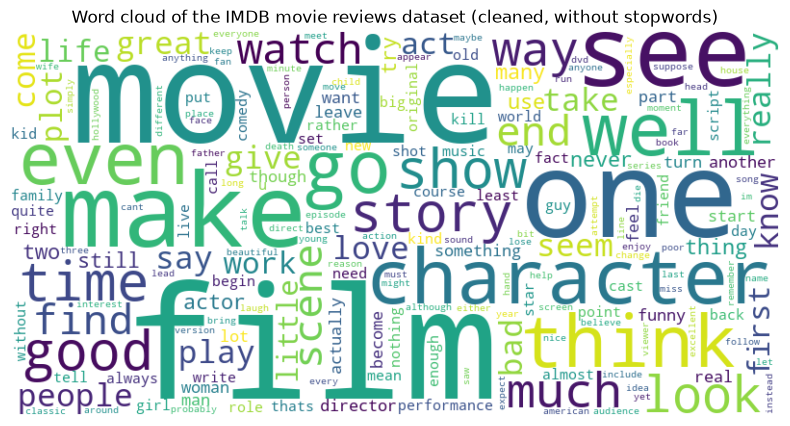

In [ ]:
# Creating a wordcloud of the entire dataset
text = " ".join(df["review_preprocessed"].astype(str).tolist())

wordcloud = WordCloud(width = 800, height = 400, background_color='white').generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  
plt.title("Word cloud of the IMDB movie reviews dataset (cleaned, without stopwords)")
plt.show()

It seems that some words, that are not stopwords, still can be regarded meaningless in this case: 'movie' and 'film' are very frequent words, and every review is in principle about movies.

In [84]:
frequentwords = ["film", "movie", "character", "one", "go"]

for word in frequentwords:
    print(f"Rate of word '{word}':", len([1 for doc in df["review"] if word in doc]) / len(df))


Rate of word 'film': 0.603
Rate of word 'movie': 0.643
Rate of word 'character': 0.341
Rate of word 'one': 0.7546
Rate of word 'go': 0.6912


In [ ]:
df["review_preprocessed"]

0       stuff go moment mj ive start listen music watc...
1       classic war world timothy hines entertain film...
2       film start manager nicholas bell give welcome ...
3       must assume praised film great film opera ever...
4       superbly trashy wondrously unpretentious 80 ex...
                              ...                        
4995    film joke comedy surely serious thriller sugge...
4996    waste time read review go see astonishingly go...
4997    secret isthis movie blow sorry spoilerin bad r...
4998    read original play think would much difficult ...
4999    story extremely uniqueits 2 pilot save earth a...
Name: review, Length: 5000, dtype: str

In [ ]:
def remove_words(doc, words):
    pattern = r"|".join(words)
    doc = re.sub(pattern, "", doc)
    doc = re.sub(r" +", " ", doc)
    return doc

# We want to remove words that are big in the wordcloud, but do not mean much: 
#   film, movie, make

words = ["film", "movie", "make"] 


df["review_preprocessed"] = df.apply(lambda x: remove_words(x["review_preprocessed"], words = words), axis = 1)

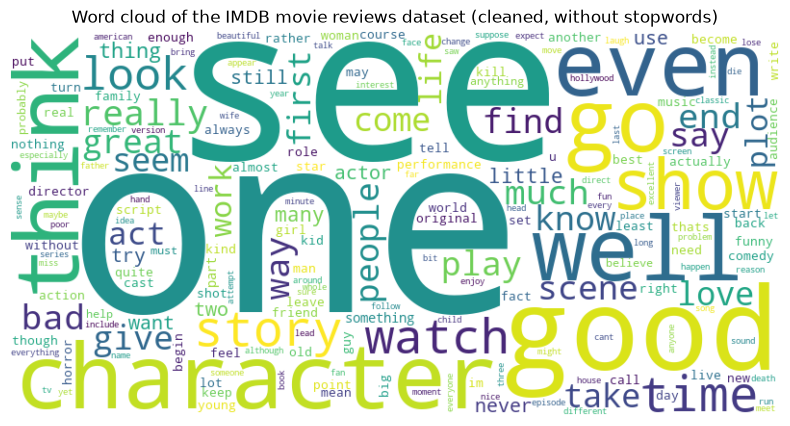

In [ ]:
# Creating a new wordcloud of the entire dataset
text = " ".join(df["review_preprocessed"].astype(str).tolist())

wordcloud = WordCloud(width = 800, height = 400, background_color='white').generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  
plt.title("Word cloud of the IMDB movie reviews dataset (cleaned, without stopwords (including 'movie', 'film' and 'make'))")
plt.show()

In [34]:
# Saving the preprocessed reviews to use them later (without havign to do the whole preprocessing again)
df.to_csv("movie_review_preprocessed.csv")

In [35]:
# Here load the preprocessed DataFrame (so you don't have to perform it each time)
df = pd.read_csv("movie_review_preprocessed.csv", index_col = 0)
df

,id,sentiment,review,review_preprocessed
0,5814_8,1,With all this stuff going down at the moment w...,stuff go moment mj ive start listen music watc...
1,2381_9,1,"\""The Classic War of the Worlds\"" by Timothy H...",classic war world timothy hines entertain obvi...
2,7759_3,0,The film starts with a manager (Nicholas Bell)...,start manager nicholas bell give welcome inve...
3,3630_4,0,It must be assumed that those who praised this...,must assume praised great opera ever read some...
4,9495_8,1,Superbly trashy and wondrously unpretentious 8...,superbly trashy wondrously unpretentious 80 ex...
...,...,...,...,...
4995,3720_2,0,Is this film a joke? Is it a comedy? Surely it...,joke comedy surely serious thriller suggestio...
4996,4229_10,1,Don't waste time reading my review. Go out and...,waste time read review go see astonishingly go...
4997,8042_3,0,"The secret is...this movie blows. Sorry, but i...",secret isthis blow sorry spoilerin bad riff kn...
4998,9669_9,1,After reading the original play I thought it w...,read original play think would much difficult ...


# Text Embedding
Now, the sentences are embedded using the sentence_transformers library.

We will use the lightweight ```sentence-transformers/all-MiniLM-L6-v2``` embedding model to generate 384-dimensional dense vector embeddings. The numerical output makes it possible to cluster using distance metrics.

In [36]:
# Using sentence-transformers/all-MiniLM-L6-v2
model_id = "sentence-transformers/all-MiniLM-L6-v2"

# HuggingFace token is secretly stored
with open("token.txt", "r") as token_file:
    hf_token = token_file.readline()

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", token = hf_token)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1640.15it/s]


In [37]:
embeddings = model.encode(list(df["review"]))
print(f"Embedded into {len(embeddings[0])}-dimensional space")

Embedded into 384-dimensional space


The text is now embedded in 384-dimensional space. Later we can compress this to ~10 features using feature reduction techniques, which will enable us to do clustering easily.

In [38]:
# Pickling the embeddings (to quickly open them in new sessions)
pickle.dump(embeddings, open('embeddings.pkl', 'wb'))

In [39]:
# Unpicklings the embeddings (loading them from a file)
loaded = pickle.load(open('embeddings.pkl', 'rb'))
print(f"Loaded embeddings \n{len(loaded)} vectors, {len(loaded[0])} dimensions")

Loaded embeddings 
5000 vectors, 384 dimensions


In [45]:
print(df["review"][0])
print(loaded[0])
print(len(loaded[0]), "dimensions")

With all this stuff going down at the moment with MJ i've started listening to his music, watching the odd documentary here and there, watched The Wiz and watched Moonwalker again. Maybe i just want to get a certain insight into this guy who i thought was really cool in the eighties just to maybe make up my mind whether he is guilty or innocent. Moonwalker is part biography, part feature film which i remember going to see at the cinema when it was originally released. Some of it has subtle messages about MJ's feeling towards the press and also the obvious message of drugs are bad m'kay.<br /><br />Visually impressive but of course this is all about Michael Jackson so unless you remotely like MJ in anyway then you are going to hate this and find it boring. Some may call MJ an egotist for consenting to the making of this movie BUT MJ and most of his fans would say that he made it for the fans which if true is really nice of him.<br /><br />The actual feature film bit when it finally star

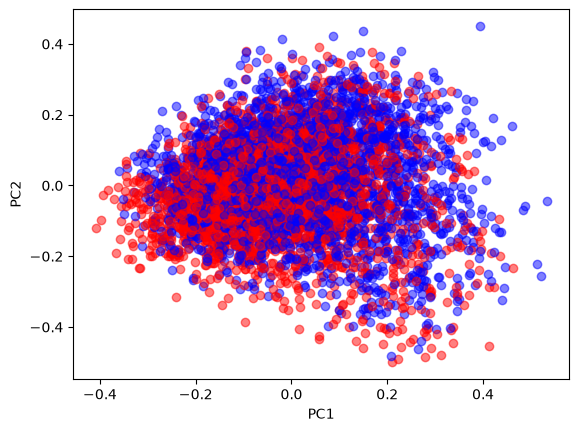

In [ ]:
# Plotting embeddings with sentiment score, compressed using PCA

pca = PCA(n_components = 2)

transformed_vectors = pca.fit_transform(loaded)

for i in range(len(loaded)):
    plt.scatter(transformed_vectors[i, 0], transformed_vectors[i, 1], c = ["r", "b"][df["sentiment"][i]], alpha = 0.5)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Transformed (PCA) sentence embeddings by sentiment score")
plt.legend
plt.show()

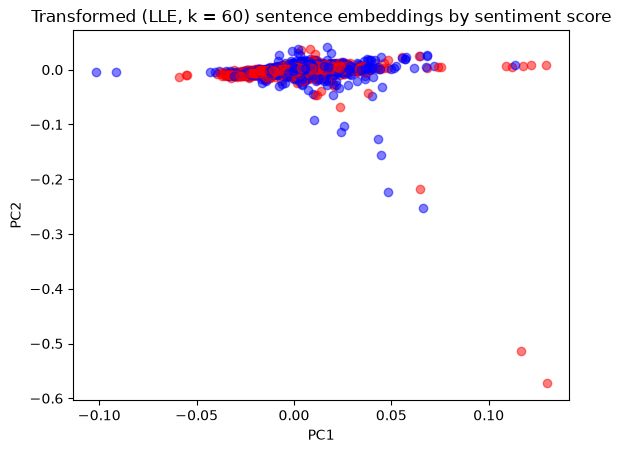

In [ ]:
k = 60

lle = LocallyLinearEmbedding(n_neighbors = k, n_components = 2)

transformed_vectors_lle = lle.fit_transform(loaded)

for i in range(len(loaded)):
    plt.scatter(transformed_vectors_lle[i, 0], transformed_vectors_lle[i, 1], c = ["r", "b"][df["sentiment"][i]], alpha = 0.5)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"Transformed (LLE, k = {k}) sentence embeddings by sentiment score")
plt.legend
plt.show()

# Topic Modeling and Text Clustering
Now, the embedded text can be clustered. The following algorithms will be used:
- Topic Modeling with Latent Dirichlet Allocation (LDA)
- GMM?

In [72]:
# Creating a corpus for Latent Dirichlet Allocation

reviews_list = [review.split() for review in list(df["review_preprocessed"])]
id2word = gensim.corpora.Dictionary(reviews_list)
corpus = [id2word.doc2bow(doc) for doc in reviews_list]

In [73]:
# Performing LDA with 10 topics
num_topics = 10

lda = gensim.models.LdaMulticore(
    corpus = corpus,
    id2word = id2word,
    num_topics = num_topics
)
lda.print_topics()

[(0,
  '0.010*"like" + 0.006*"see" + 0.006*"well" + 0.005*"good" + 0.005*"one" + 0.005*"really" + 0.004*"look" + 0.004*"first" + 0.004*"get" + 0.004*"time"'),
 (1,
  '0.007*"one" + 0.007*"like" + 0.006*"get" + 0.005*"time" + 0.005*"great" + 0.004*"good" + 0.004*"love" + 0.004*"story" + 0.004*"see" + 0.004*"also"'),
 (2,
  '0.007*"see" + 0.007*"one" + 0.006*"get" + 0.005*"good" + 0.005*"go" + 0.005*"character" + 0.004*"like" + 0.004*"time" + 0.004*"love" + 0.004*"watch"'),
 (3,
  '0.007*"like" + 0.007*"character" + 0.006*"one" + 0.005*"even" + 0.004*"go" + 0.004*"show" + 0.004*"well" + 0.004*"watch" + 0.004*"would" + 0.004*"come"'),
 (4,
  '0.008*"see" + 0.007*"good" + 0.006*"like" + 0.005*"get" + 0.005*"go" + 0.005*"give" + 0.004*"one" + 0.004*"even" + 0.004*"time" + 0.004*"story"'),
 (5,
  '0.011*"one" + 0.007*"like" + 0.007*"see" + 0.007*"get" + 0.006*"time" + 0.005*"go" + 0.005*"think" + 0.005*"story" + 0.004*"character" + 0.004*"watch"'),
 (6,
  '0.009*"one" + 0.007*"like" + 0.006*

In [99]:
document_topics = {}

topics_per_doc = lda.get_document_topics(corpus)
for i, doc in enumerate(topics_per_doc):
    topic = max(doc)[0]
    if topic in document_topics:
        document_topics[topic].append(i)
    else:
        document_topics[topic] = [i]

print("Amount of documents assigned per topic:")
for topic in document_topics:
    print(topic, len(document_topics[topic]))

Amount of documents assigned per topic:
8 1142
7 795
9 954
6 684
5 588
1 300
3 81
2 124
4 199
0 133


In [75]:
# Visualizing the results using the pyLDAvis library

pyLDAvis.enable_notebook()

LDAvis_prepared = pyLDAvis.gensim.prepare(lda, corpus, id2word)
with open("results/ldavis_10_docs", 'wb') as f:
    pickle.dump(LDAvis_prepared, f)

In [76]:
with open("results/ldavis_10_docs", 'rb') as f:
    LDAvis_prepared = pickle.load(f)

pyLDAvis.save_html(LDAvis_prepared, './results/ldavis_10.html')
LDAvis_prepared

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
5      0.011768 -0.007876       1        1  16.327613
6      0.006560 -0.002485       2        1  16.109473
8      0.011100  0.004052       3        1  15.556784
7      0.009000 -0.005907       4        1  14.903989
9      0.004981  0.003589       5        1  10.980750
1     -0.000365 -0.005059       6        1  10.183137
0     -0.000219  0.015726       7        1   5.178265
4     -0.006325  0.008708       8        1   5.056802
2     -0.016390 -0.016173       9        1   3.518171
3     -0.020110  0.005426      10        1   2.185016, topic_info=          Term         Freq        Total Category  logprob  loglift
77        like  3994.000000  3994.000000  Default  30.0000  30.0000
122        see  3740.000000  3740.000000  Default  29.0000  29.0000
20   character  2596.000000  2596.000000  Default  28.0000  28.0000
277       good  3110.000000  3110.000000  Default  27.0000  27.0000
55          go  2573.000000  2573.000000  Default  26.0000  26.0000
..         ...          ...          ...      ...      ...      ...
136      think    34.441017  2208.176494  Topic10  -5.9188  -0.3371
366      story    33.427783  2361.239684  Topic10  -5.9487  -0.4340
72        know    28.912918  1655.502289  Topic10  -6.0938  -0.2240
665       time    34.019522  2916.438272  Topic10  -5.9312  -0.6276
8          bad    29.143849  2280.603925  Topic10  -6.0858  -0.5364

[869 rows x 6 columns], token_table=       Topic      Freq     Term
term                           
19635      3  0.511510      109
2994       1  0.146438        2
2994       2  0.114488        2
2994       3  0.141113        2
2994       4  0.143776        2
...      ...       ...      ...
4141       9  0.026841   zombie
4141      10  0.008947   zombie
29665      2  0.507712    zorak
48444      4  0.421187  zucovic
48444      7  0.421187  zucovic

[2119 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[6, 7, 9, 8, 10, 2, 1, 5, 3, 4])